# **Data Exploration**

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
dataset = pd.read_csv('/content/COMP1801_Coursework_Dataset.csv')

In [3]:
dataset.shape

(1000, 16)

In [4]:
dataset.head()

,Lifespan,partType,microstructure,coolingRate,quenchTime,forgeTime,HeatTreatTime,Nickel%,Iron%,Cobalt%,Chromium%,smallDefects,largeDefects,sliverDefects,seedLocation,castType
0,1469.17,Nozzle,equiGrain,13,3.84,6.47,46.87,65.73,16.52,16.82,0.93,10,0,0,Bottom,Die
1,1793.64,Block,singleGrain,19,2.62,3.48,44.70,54.22,35.38,6.14,4.26,19,0,0,Bottom,Investment
2,700.60,Blade,equiGrain,28,0.76,1.34,9.54,51.83,35.95,8.81,3.41,35,3,0,Bottom,Investment
3,1082.10,Nozzle,colGrain,9,2.01,2.19,20.29,57.03,23.33,16.86,2.78,0,1,0,Top,Continuous
4,1838.83,Blade,colGrain,16,4.13,3.87,16.13,59.62,27.37,11.45,1.56,10,0,0,Top,Die


In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Lifespan        1000 non-null   float64
 1   partType        1000 non-null   object 
 2   microstructure  1000 non-null   object 
 3   coolingRate     1000 non-null   int64  
 4   quenchTime      1000 non-null   float64
 5   forgeTime       1000 non-null   float64
 6   HeatTreatTime   1000 non-null   float64
 7   Nickel%         1000 non-null   float64
 8   Iron%           1000 non-null   float64
 9   Cobalt%         1000 non-null   float64
 10  Chromium%       1000 non-null   float64
 11  smallDefects    1000 non-null   int64  
 12  largeDefects    1000 non-null   int64  
 13  sliverDefects   1000 non-null   int64  
 14  seedLocation    1000 non-null   object 
 15  castType        1000 non-null   object 
dtypes: float64(8), int64(4), object(4)
memory usage: 125.1+ KB


In [6]:
dataset.describe()

,Lifespan,coolingRate,quenchTime,forgeTime,HeatTreatTime,Nickel%,Iron%,Cobalt%,Chromium%,smallDefects,largeDefects,sliverDefects
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1298.556320,17.639000,2.764230,5.464600,30.194510,60.243080,24.553580,12.434690,2.768650,17.311000,0.550000,0.292000
std,340.071434,7.491783,1.316979,2.604513,16.889415,5.790475,7.371737,4.333197,1.326496,12.268365,1.163982,1.199239
min,417.990000,5.000000,0.500000,1.030000,1.030000,50.020000,6.660000,5.020000,0.510000,0.000000,0.000000,0.000000
25%,1047.257500,11.000000,1.640000,3.170000,16.185000,55.287500,19.387500,8.597500,1.590000,7.000000,0.000000,0.000000
50%,1266.040000,18.000000,2.755000,5.475000,29.365000,60.615000,24.690000,12.585000,2.865000,18.000000,0.000000,0.000000
75%,1563.050000,24.000000,3.970000,7.740000,44.955000,65.220000,29.882500,16.080000,3.922500,26.000000,0.000000,0.000000
max,2134.530000,30.000000,4.990000,10.000000,59.910000,69.950000,43.650000,19.990000,4.990000,61.000000,4.000000,8.000000


In [7]:
dataset.isnull().sum()

,0
Lifespan,0
partType,0
microstructure,0
coolingRate,0
quenchTime,0
forgeTime,0
HeatTreatTime,0
Nickel%,0
Iron%,0
Cobalt%,0


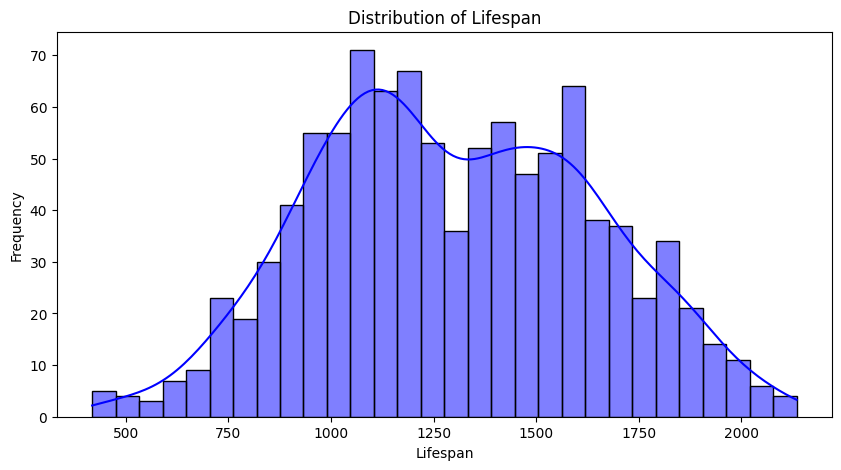

In [8]:
# Lifespan Distribution
plt.figure(figsize=(10, 5))
sns.histplot(dataset['Lifespan'], kde=True, color='blue', bins=30)
plt.title('Distribution of Lifespan')
plt.xlabel('Lifespan')
plt.ylabel('Frequency')
plt.show()

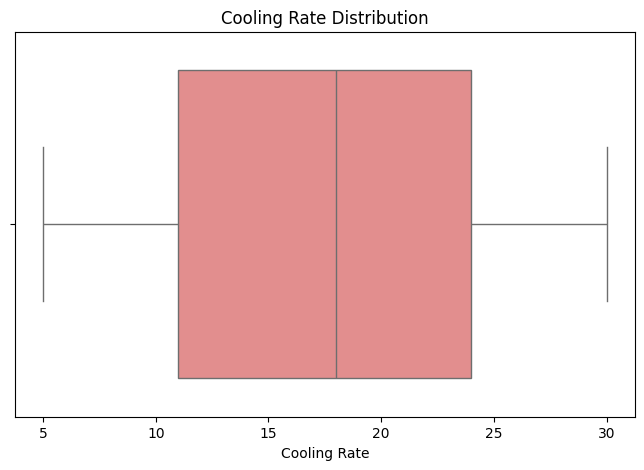

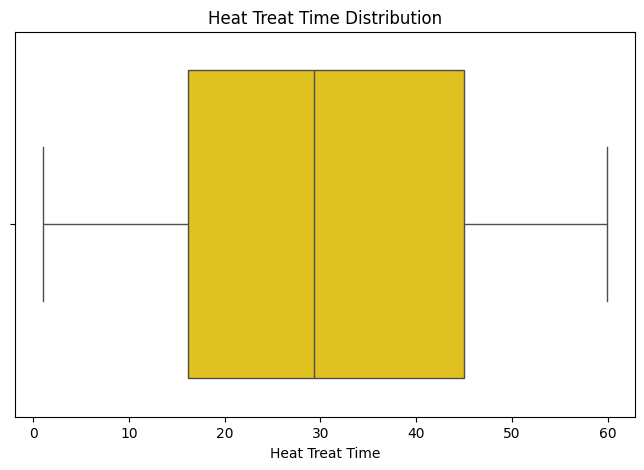

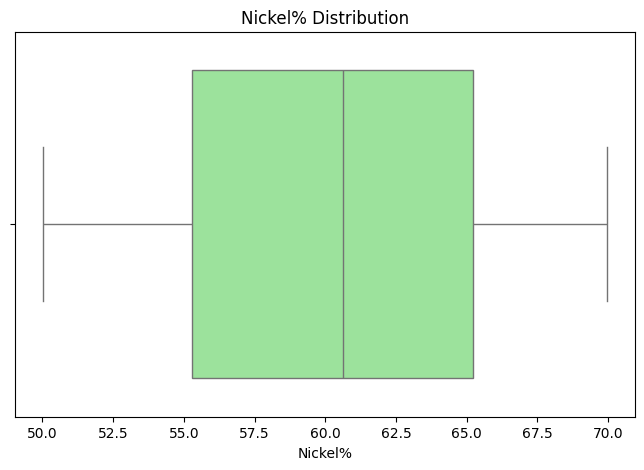

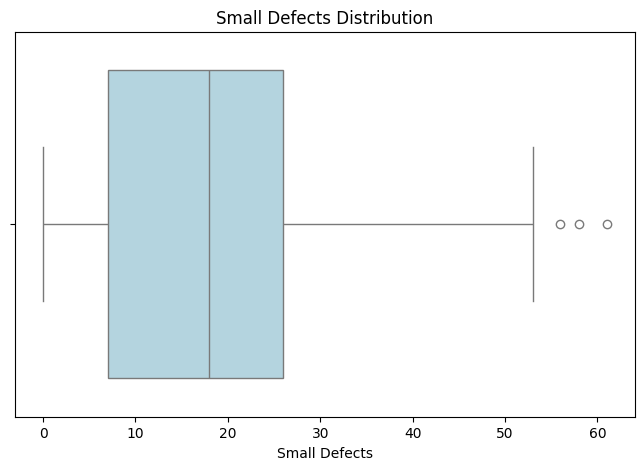

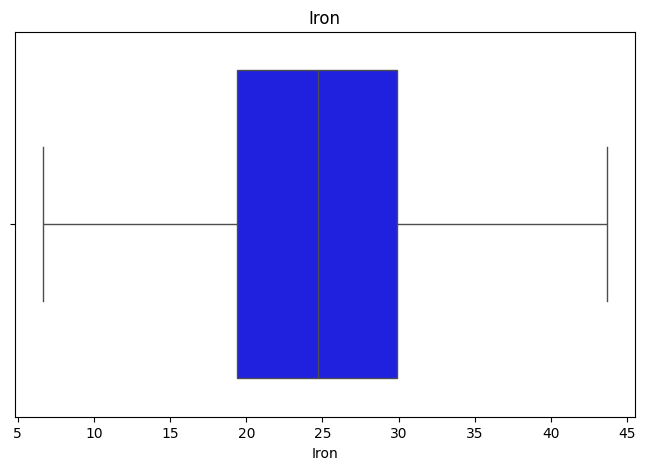

In [9]:
# Boxplots for Cooling Rate
plt.figure(figsize=(8, 5))
sns.boxplot(data=dataset, x='coolingRate', color='lightcoral')
plt.title('Cooling Rate Distribution')
plt.xlabel('Cooling Rate')
plt.show()

# Boxplots for Heat Treat Time
plt.figure(figsize=(8, 5))
sns.boxplot(data=dataset, x='HeatTreatTime', color='gold')
plt.title('Heat Treat Time Distribution')
plt.xlabel('Heat Treat Time')
plt.show()

# Boxplots for Nickel Percentage
plt.figure(figsize=(8, 5))
sns.boxplot(data=dataset, x='Nickel%', color='lightgreen')
plt.title('Nickel% Distribution')
plt.xlabel('Nickel%')
plt.show()

# Boxplots for Small Defects
plt.figure(figsize=(8, 5))
sns.boxplot(data=dataset, x='smallDefects', color='lightblue')
plt.title('Small Defects Distribution')
plt.xlabel('Small Defects')
plt.show()

# Boxplots for Iron
plt.figure(figsize=(8, 5))
sns.boxplot(data=dataset, x='Iron%', color='blue')
plt.title('Iron')
plt.xlabel('Iron')
plt.show()

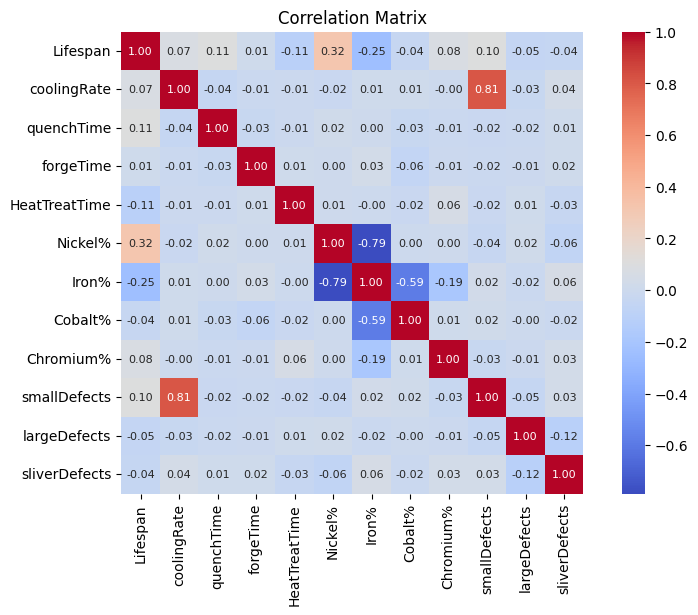

In [10]:
# Correlation Matrix
numeric_dataset = dataset.select_dtypes(include=['number'])
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_dataset.corr(), cbar=True, square=True, fmt='.2f', annot=True, annot_kws={'size':8}, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# **Regression Implementation**

### Linear Regression

**With Categorical Feature**

In [11]:
# Define features and target variable
categorical_features = ['partType', 'microstructure', 'seedLocation', 'castType']
numerical_features = ['coolingRate', 'quenchTime', 'HeatTreatTime', 'Nickel%', 'Iron%', 'Chromium%', 'smallDefects']
target = 'Lifespan'

In [12]:
# Separate features and target
X = dataset[categorical_features + numerical_features]
y = dataset[target]

**With One Hot Encoding**


Validation Results for Polynomial Regression:
   Degree  Validation MAE  Validation MSE  Validation R²
0       1      263.639604    98599.521824       0.120046
1       2      143.650248    29607.271778       0.735769
2       3      251.373394   100978.154857       0.098818
3       4      214.332164    99169.281596       0.114961

Best Degree for Polynomial Features: 2

Test Set Performance for Best Polynomial Regression Model:
MAE: 112.03
MSE: 19054.56
R²: 0.80


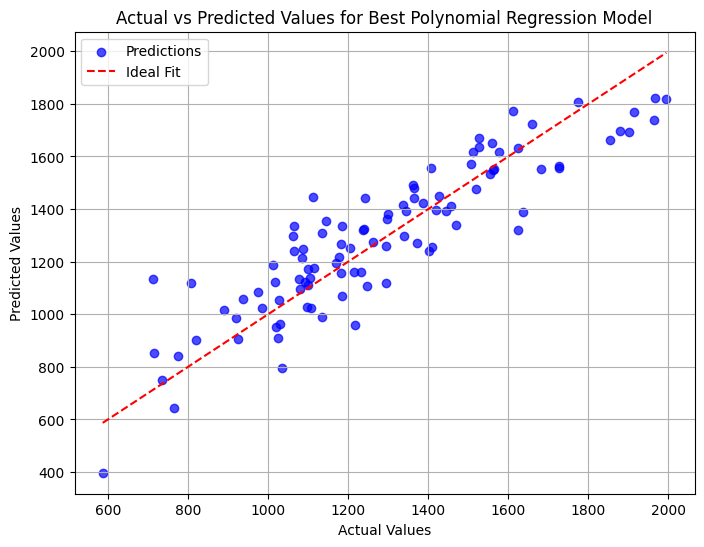

In [13]:
# One-hot encoding for categorical features, standard scaling for numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)  # Updated argument
    ]
)

# Train-Test-Validation Split (80-10-10)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)

# Polynomial Regression Experimentation
degrees = [1, 2, 3, 4]  # Degrees to test
results = []

for degree in degrees:
    # Polynomial Features
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_preprocessed)
    X_val_poly = poly.transform(X_val_preprocessed)
    X_test_poly = poly.transform(X_test_preprocessed)

    # Train Linear Regression Model
    linear_model = LinearRegression()
    linear_model.fit(X_train_poly, y_train)

    # Evaluate on Validation Set
    y_val_pred = linear_model.predict(X_val_poly)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mse = mean_squared_error(y_val, y_val_pred)
    val_r2 = r2_score(y_val, y_val_pred)

    # Store Validation Results
    results.append({
        'Degree': degree,
        'Validation MAE': val_mae,
        'Validation MSE': val_mse,
        'Validation R²': val_r2
    })

results_df = pd.DataFrame(results)
print("\nValidation Results for Polynomial Regression:")
print(results_df)

# Select the best degree based on Validation MSE
best_degree = results_df.loc[results_df['Validation MSE'].idxmin(), 'Degree']
print(f"\nBest Degree for Polynomial Features: {best_degree}")

# Train Final Model on Combined Training + Validation Set
X_train_val_preprocessed = np.vstack((X_train_preprocessed, X_val_preprocessed))
y_train_val = np.concatenate((y_train, y_val))

poly = PolynomialFeatures(degree=best_degree)
X_train_val_poly = poly.fit_transform(X_train_val_preprocessed)

linear_model = LinearRegression()
linear_model.fit(X_train_val_poly, y_train_val)

# Evaluate on the Test Set
X_test_poly = poly.transform(X_test_preprocessed)
y_test_pred = linear_model.predict(X_test_poly)

# Compute Test Set Metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Print Test Set Performance
print("\nTest Set Performance for Best Polynomial Regression Model:")
print(f"MAE: {test_mae:.2f}")
print(f"MSE: {test_mse:.2f}")
print(f"R²: {test_r2:.2f}")

# Create a scatter plot for actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='blue', label='Predictions')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values for Best Polynomial Regression Model')
plt.legend()
plt.grid()
plt.show()




**Only Numeric Features**

In [14]:
# Separate features and target
X = dataset[numerical_features]
y = dataset[target]


Validation Results for Polynomial Regression:
   Degree  Validation MAE  Validation MSE  Validation R²
0       1      269.786269   106711.007147       0.047655
1       2      157.994588    37482.677589       0.665485
2       3      171.122425    43526.228608       0.611549
3       4      164.126824    40837.577226       0.635544

Best Degree for Polynomial Features: 2

Test Set Performance for Best Polynomial Regression Model:
MAE: 118.29
MSE: 22290.91
R²: 0.77


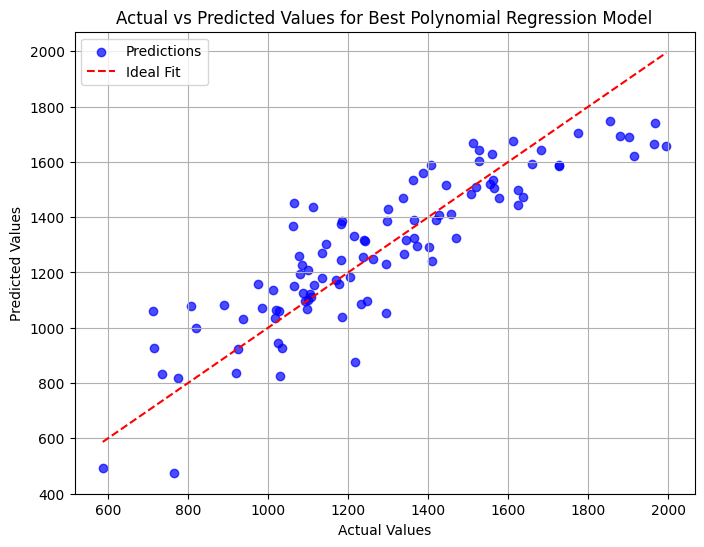

In [15]:
# Train-Test-Validation Split (80-10-10)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Feature Scaling: Standardizing the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Polynomial Regression Experimentation
degrees = [1, 2, 3, 4]
results = []

for degree in degrees:
    # Polynomial Features
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_val_poly = poly.transform(X_val_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    # Train Linear Regression Model
    linear_model = LinearRegression()
    linear_model.fit(X_train_poly, y_train)

    # Evaluate on Validation Set
    y_val_pred = linear_model.predict(X_val_poly)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mse = mean_squared_error(y_val, y_val_pred)
    val_r2 = r2_score(y_val, y_val_pred)

    # Store Validation Results
    results.append({
        'Degree': degree,
        'Validation MAE': val_mae,
        'Validation MSE': val_mse,
        'Validation R²': val_r2
    })

results_df = pd.DataFrame(results)
print("\nValidation Results for Polynomial Regression:")
print(results_df)

# Select the best degree based on Validation MSE
best_degree = results_df.loc[results_df['Validation MSE'].idxmin(), 'Degree']
print(f"\nBest Degree for Polynomial Features: {best_degree}")

# Train Final Model on Combined Training + Validation Set
X_train_val_scaled = np.vstack((X_train_scaled, X_val_scaled))
y_train_val = np.concatenate((y_train, y_val))

poly = PolynomialFeatures(degree=best_degree)
X_train_val_poly = poly.fit_transform(X_train_val_scaled)

linear_model = LinearRegression()
linear_model.fit(X_train_val_poly, y_train_val)

# Evaluate on the Test Set
X_test_poly = poly.transform(X_test_scaled)  # Transform the test set using the same fitted PolynomialFeatures
y_test_pred = linear_model.predict(X_test_poly)

# Compute Test Set Metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Print Test Set Performance
print("\nTest Set Performance for Best Polynomial Regression Model:")
print(f"MAE: {test_mae:.2f}")
print(f"MSE: {test_mse:.2f}")
print(f"R²: {test_r2:.2f}")

# Create a scatter plot for actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='blue', label='Predictions')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values for Best Polynomial Regression Model')
plt.legend()
plt.grid()
plt.show()


# **ANN Model**

**With One Hot Encoding**

In [16]:
# Define features and target variable
categorical_features = ['partType', 'microstructure', 'seedLocation', 'castType']
numerical_features = ['coolingRate', 'quenchTime', 'HeatTreatTime', 'Nickel%', 'Iron%', 'Chromium%', 'smallDefects']
target = 'Lifespan'

# Separate features and target
X = dataset[categorical_features + numerical_features]
y = dataset[target]

# One-hot encoding for categorical features, standard scaling for numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500}
Training with parameters: {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500}


...

Training with parameters: {'hidden_layer_sizes': (100, 50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (100, 50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250}
                                           Parameters          MAE  \
0   {'hidden_layer_sizes': (50,), 'activation': 'r...   423.629775   
1   {'hidden_layer_sizes': (50,), 'activation': 'r...   271.258101   
2   {'hidden_layer_sizes': (50,), 'activation': 'r...   143.306741   
3   {'hidden_layer_sizes': (100,), 'activation': '...   369.233307   
4   {'hidden_layer_sizes': (100,), 'activation': '...   270.809815   
5   {'hidden_layer_sizes': (100,), 'activation': '...   283.645207   
6   {'hidden_layer_sizes': (100, 50), 'activation'...   292.337838   
7   {'hidden_layer_sizes': (100, 50), 'activation'...   274.173351   
8   {'hidden_layer_sizes': (100, 50), 'activation'...   110.806632   
9   {'hidden_layer_sizes': (50,), 'activation': 'r...   957.998548   
10  {'hidden_layer_sizes': (50,), 'activation': 'r...   305.108694   
11  {'hidden_layer_sizes': (50,), 

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(



Test Set Performance of the Best Model:
MAE: 70.47
MSE: 7774.35
R²: 0.92


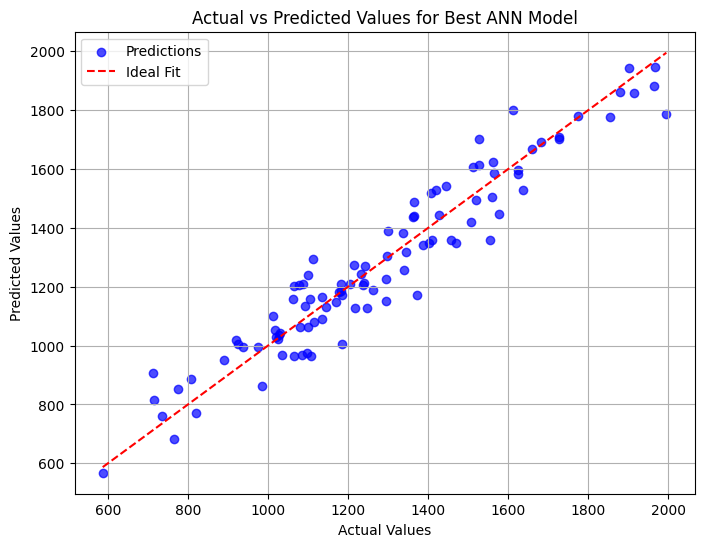

In [17]:
# Split the dataset into Train (80%) and Temp (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the Temp set into Validation (10%) and Test (10%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Scale the numerical features
X_train_preprocess = preprocessor.fit_transform(X_train)
X_val_preprocess = preprocessor.transform(X_val)
X_test_preprocess = preprocessor.transform(X_test)

# Define the hyper-parameter grid for ANN
mlp_params = [
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
]

# Tune hyperparameters manually using the Validation set
results = []
for params in mlp_params:
    print(f"Training with parameters: {params}")
    model = MLPRegressor(
        hidden_layer_sizes=params['hidden_layer_sizes'],
        activation=params['activation'],
        learning_rate_init=params['learning_rate_init'],
        max_iter=params['max_iter'],
        random_state=42
    )
    model.fit(X_train_preprocess, y_train)
    y_val_pred = model.predict(X_val_preprocess)

    # Calculate metrics on Validation set
    mae = mean_absolute_error(y_val, y_val_pred)
    mse = mean_squared_error(y_val, y_val_pred)
    r2 = r2_score(y_val, y_val_pred)

    # Store results
    results.append({
        'Parameters': params,
        'MAE': mae,
        'MSE': mse,
        'R²': r2
    })


results_df = pd.DataFrame(results)
print(results_df)

best_params = results_df.loc[results_df['MSE'].idxmin(), 'Parameters']
print("\nBest Parameters Based on Validation MSE:")
print(best_params)

# Train the Best Model on the Combined Training and Validation Set
X_train_val = np.vstack((X_train_preprocess, X_val_preprocess))
y_train_val = np.concatenate((y_train, y_val))
best_model = MLPRegressor(
    hidden_layer_sizes=best_params['hidden_layer_sizes'],
    activation=best_params['activation'],
    learning_rate_init=best_params['learning_rate_init'],
    max_iter=best_params['max_iter'],
    random_state=42
)
best_model.fit(X_train_val, y_train_val)

# Evaluate the final model on the Test Set
y_test_pred = best_model.predict(X_test_preprocess)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Print Test Set Performance
print("\nTest Set Performance of the Best Model:")
print(f"MAE: {test_mae:.2f}")
print(f"MSE: {test_mse:.2f}")
print(f"R²: {test_r2:.2f}")

# Create a scatter plot for actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='blue', label='Predictions')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values for Best ANN Model')
plt.legend()
plt.grid(True)
plt.show()



**Numerical Features**

In [18]:
# Separate features and target
X = dataset[numerical_features]
y = dataset[target]

Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500}
Training with parameters: {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500}


...

Training with parameters: {'hidden_layer_sizes': (100, 50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250}


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with parameters: {'hidden_layer_sizes': (100, 50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250}
                                           Parameters          MAE  \
0   {'hidden_layer_sizes': (50,), 'activation': 'r...   747.394204   
1   {'hidden_layer_sizes': (50,), 'activation': 'r...   181.790970   
2   {'hidden_layer_sizes': (50,), 'activation': 'r...   271.585408   
3   {'hidden_layer_sizes': (100,), 'activation': '...   479.699159   
4   {'hidden_layer_sizes': (100,), 'activation': '...   149.117698   
5   {'hidden_layer_sizes': (100,), 'activation': '...   271.250048   
6   {'hidden_layer_sizes': (100, 50), 'activation'...   205.807442   
7   {'hidden_layer_sizes': (100, 50), 'activation'...   270.942011   
8   {'hidden_layer_sizes': (100, 50), 'activation'...   262.747452   
9   {'hidden_layer_sizes': (50,), 'activation': 'r...  1132.240462   
10  {'hidden_layer_sizes': (50,), 'activation': 'r...   305.332964   
11  {'hidden_layer_sizes': (50,), 

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(



Test Set Performance of the Best Model:
MAE: 85.46
MSE: 11559.95
R²: 0.88


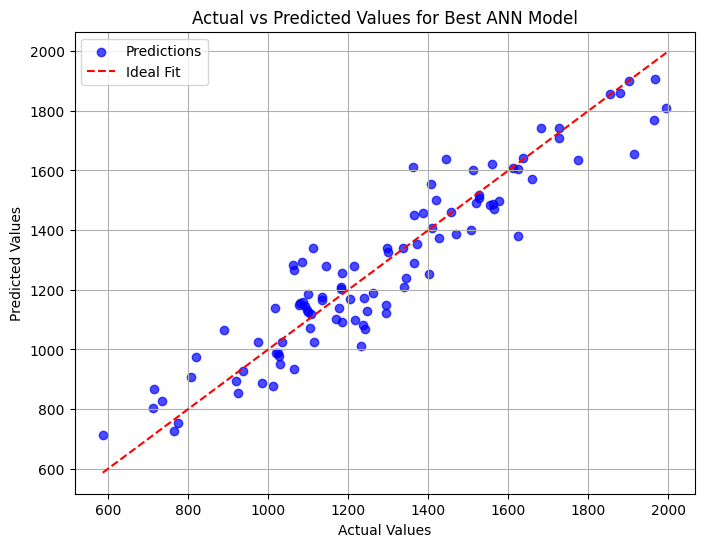

In [19]:
# Split the dataset into Train (80%) and Temp (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the Temp set into Validation (10%) and Test (10%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Scale the numerical features
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_val_scale = scaler.transform(X_val)
X_test_scale = scaler.transform(X_test)

# Define the hyper-parameter grid for ANN
mlp_params = [
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'relu', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 500},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 500},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (50,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.001, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.01, 'max_iter': 250},
    {'hidden_layer_sizes': (100,50), 'activation': 'tanh', 'learning_rate_init': 0.1, 'max_iter': 250},
]

# Tune hyperparameters manually using the Validation set
results = []
for params in mlp_params:
    print(f"Training with parameters: {params}")
    model = MLPRegressor(
        hidden_layer_sizes=params['hidden_layer_sizes'],
        activation=params['activation'],
        learning_rate_init=params['learning_rate_init'],
        max_iter=params['max_iter'],
        random_state=42
    )
    model.fit(X_train_scale, y_train)
    y_val_pred = model.predict(X_val_scale)

    # Calculate metrics on Validation set
    mae = mean_absolute_error(y_val, y_val_pred)
    mse = mean_squared_error(y_val, y_val_pred)
    r2 = r2_score(y_val, y_val_pred)

    # Store results
    results.append({
        'Parameters': params,
        'MAE': mae,
        'MSE': mse,
        'R²': r2
    })


results_df = pd.DataFrame(results)
print(results_df)


best_params = results_df.loc[results_df['MSE'].idxmin(), 'Parameters']
print("\nBest Parameters Based on Validation MSE:")
print(best_params)

# Train the Best Model on the Combined Training and Validation Set
X_train_val = np.vstack((X_train_scale, X_val_scale))
y_train_val = np.concatenate((y_train, y_val))
best_model = MLPRegressor(
    hidden_layer_sizes=best_params['hidden_layer_sizes'],
    activation=best_params['activation'],
    learning_rate_init=best_params['learning_rate_init'],
    max_iter=best_params['max_iter'],
    random_state=42
)
best_model.fit(X_train_val, y_train_val)

# Evaluate the final model on the Test Set
y_test_pred = best_model.predict(X_test_scale)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Print Test Set Performance
print("\nTest Set Performance of the Best Model:")
print(f"MAE: {test_mae:.2f}")
print(f"MSE: {test_mse:.2f}")
print(f"R²: {test_r2:.2f}")

# Create a scatter plot for actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='blue', label='Predictions')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values for Best ANN Model')
plt.legend()
plt.grid(True)
plt.show()


# **Classification Implementation**

Cluster Distribution:
cluster_labels
0    346
2    332
1    322
Name: count, dtype: int64


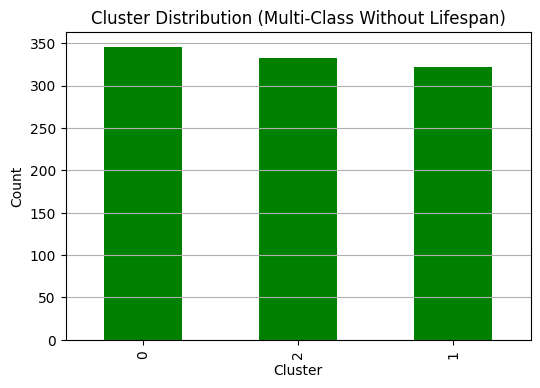

In [20]:
dataset = pd.read_csv('/content/COMP1801_Coursework_Dataset.csv')

# Exclude Lifespan column for clustering input
numerical_data = dataset[numerical_features]

# Standardize numerical features
scaler = StandardScaler()
numerical_data_scaled = scaler.fit_transform(numerical_data)

# Apply K-Means clustering
k = 3  #
kmeans = KMeans(n_clusters=k, random_state=42)

# Fit K-Means on scaled numerical features
dataset['cluster_labels'] = kmeans.fit_predict(numerical_data_scaled)

# Check the distribution of clusters
cluster_distribution = dataset['cluster_labels'].value_counts()
print("Cluster Distribution:")
print(cluster_distribution)

plt.figure(figsize=(6, 4))
cluster_distribution.plot(kind='bar', color='green')
plt.title('Cluster Distribution (Multi-Class Without Lifespan)')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()


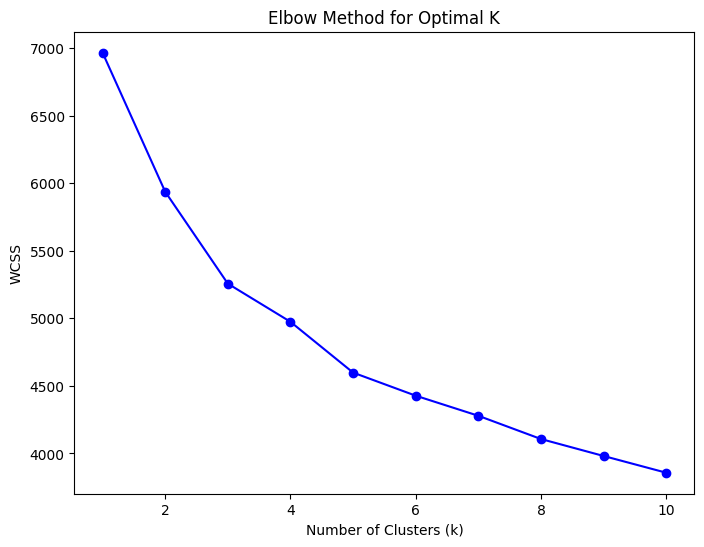

In [21]:
# Elbow Method to find the optimal k
wcss = []
# Test for k = 1 to 10
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_train_preprocessed)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), wcss, marker='o', color='b')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.show()


In [22]:
# Use the cluster labels as a new output class for multi-class classification
dataset['multi_class_labels'] = dataset['cluster_labels']

# Checking the distribution of multi-class labels
print("\nMulti-Class Label Distribution:")
print(dataset['multi_class_labels'].value_counts())



Multi-Class Label Distribution:
multi_class_labels
0    346
2    332
1    322
Name: count, dtype: int64


In [23]:
# Add binary labels based on the 1500-hour threshold
dataset['1500_labels'] = (dataset['Lifespan'] >= 1500).astype(int)

# Define features and target for binary classification
X = dataset.drop(['Lifespan', 'multi_class_labels'], axis=1)
y_binary = dataset['1500_labels']

# Train-Test-Validation Split (80-10-10)
X_train, X_temp, y_train, y_temp = train_test_split(X, y_binary, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Define preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),  # Scale numerical features
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)  # Encode categorical features
    ]
)

# Apply preprocessing
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)


In [24]:
# Adjusted hyperparameter grid for Logistic Regression
log_reg_params = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'saga', 'lbfgs'],
}

log_reg = LogisticRegression(max_iter=500, random_state=42)
log_reg_grid = GridSearchCV(estimator=log_reg, param_grid=log_reg_params, scoring='accuracy', cv=5, verbose=1, error_score='raise')
log_reg_grid.fit(X_train_preprocessed, y_train)

# Logistic Regression Hyperparameter Results
log_reg_results = pd.DataFrame(log_reg_grid.cv_results_)
log_reg_results_summary = log_reg_results[
    ['param_C', 'param_solver', 'mean_test_score', 'std_test_score']
].copy()
log_reg_results_summary.rename(columns={
    'param_C': 'C',
    'param_solver': 'Solver',
    'mean_test_score': 'Mean Accuracy (CV)',
    'std_test_score': 'Std Dev (CV)'
}, inplace=True)

print("\nLogistic Regression Hyperparameter Tuning Results:")
print(log_reg_results_summary)

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Logistic Regression Hyperparameter Tuning Results:
        C     Solver  Mean Accuracy (CV)  Std Dev (CV)
0    0.01  liblinear             0.67500      0.018957
1    0.01       saga             0.68000      0.012119
2    0.01      lbfgs             0.68000      0.012119
3    0.10  liblinear             0.68375      0.026101
4    0.10       saga             0.68125      0.030619
5    0.10      lbfgs             0.68125      0.030619
6    1.00  liblinear             0.67500      0.028504
7    1.00       saga             0.67500      0.028504
8    1.00      lbfgs             0.67500      0.028504
9   10.00  liblinear             0.67500      0.028504
10  10.00       saga             0.67500      0.028504
11  10.00      lbfgs             0.67500      0.028504


In [25]:
# ANN: Hyperparameter Tuning
ann_params = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50)],
    'activation': ['relu', 'tanh'],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [500, 1000]
}

ann_model = MLPClassifier(random_state=42)
ann_grid = GridSearchCV(estimator=ann_model, param_grid=ann_params, scoring='accuracy', cv=5, verbose=1)
ann_grid.fit(X_train_preprocessed, y_train)

# ANN Hyperparameter Results
ann_results = pd.DataFrame(ann_grid.cv_results_)
ann_results_summary = ann_results[
    ['param_hidden_layer_sizes', 'param_activation', 'param_learning_rate_init', 'param_max_iter', 'mean_test_score', 'std_test_score']
].copy()
ann_results_summary.rename(columns={
    'param_hidden_layer_sizes': 'Hidden Layer Sizes',
    'param_activation': 'Activation Function',
    'param_learning_rate_init': 'Learning Rate',
    'param_max_iter': 'Max Iterations',
    'mean_test_score': 'Mean Accuracy (CV)',
    'std_test_score': 'Std Dev (CV)'
}, inplace=True)

print("\nANN Hyperparameter Tuning Results:")
print(ann_results_summary)


Fitting 5 folds for each of 24 candidates, totalling 120 fits


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptro


ANN Hyperparameter Tuning Results:
   Hidden Layer Sizes Activation Function  Learning Rate  Max Iterations  \
0               (50,)                relu          0.001             500   
1               (50,)                relu          0.001            1000   
2               (50,)                relu          0.010             500   
3               (50,)                relu          0.010            1000   
4              (100,)                relu          0.001             500   
5              (100,)                relu          0.001            1000   
6              (100,)                relu          0.010             500   
7              (100,)                relu          0.010            1000   
8           (100, 50)                relu          0.001             500   
9           (100, 50)                relu          0.001            1000   
10          (100, 50)                relu          0.010             500   
11          (100, 50)                relu          0


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.89      0.83        74
           1       0.47      0.27      0.34        26

    accuracy                           0.73       100
   macro avg       0.62      0.58      0.59       100
weighted avg       0.70      0.73      0.70       100


ANN Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95        74
           1       0.83      0.92      0.87        26

    accuracy                           0.93       100
   macro avg       0.90      0.93      0.91       100
weighted avg       0.93      0.93      0.93       100



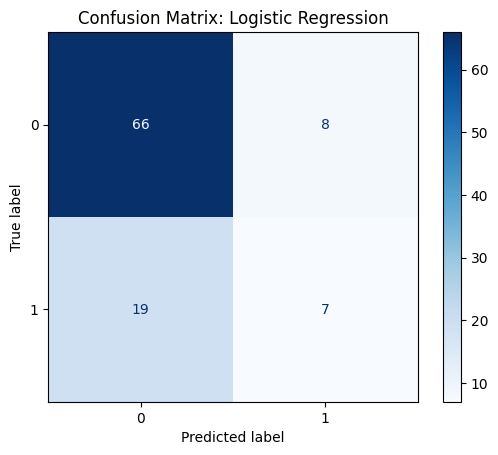

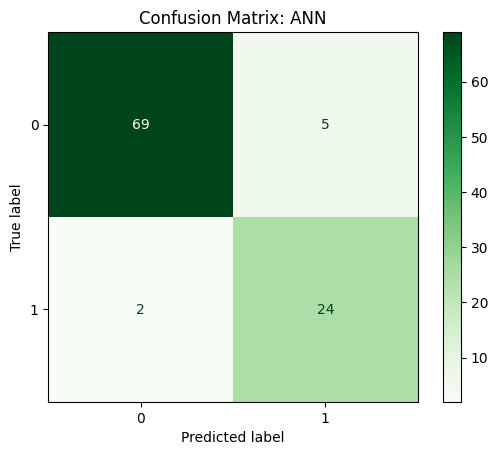

In [26]:
# Get predictions from the trained Logistic Regression model
y_pred_log_reg = log_reg_grid.predict(X_test_preprocessed)
# Get predictions from the trained ANN model
y_pred_ann = ann_grid.predict(X_test_preprocessed)

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_log_reg))

# Evaluation: ANN
print("\nANN Classification Report:")
print(classification_report(y_test, y_pred_ann))

# Confusion Matrix for Logistic Regression
cm_log_reg = confusion_matrix(y_test, y_pred_log_reg)
disp_log_reg = ConfusionMatrixDisplay(confusion_matrix=cm_log_reg, display_labels=np.unique(y_test))
disp_log_reg.plot(cmap='Blues')
plt.title("Confusion Matrix: Logistic Regression")
plt.show()

# Confusion Matrix for ANN
cm_ann = confusion_matrix(y_test, y_pred_ann)
disp_ann = ConfusionMatrixDisplay(confusion_matrix=cm_ann, display_labels=np.unique(y_test))
disp_ann.plot(cmap='Greens')
plt.title("Confusion Matrix: ANN")
plt.show()